<a href="https://colab.research.google.com/github/luiscalvi/CSC349/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Luis Calvillo - Assignment 5

Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.



Here I load the dataset using Panda. The set has 768 patient records with eight medical features and one target variable. The goal is to see if a patient has diabetes or does not.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

columns = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


Task 2: Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

Here we examine the dataset using head, info and describe. These methods show us sample records, data types, and stats. We identify zero values that may have missing measurements like glucose, blood pressure, insulin and BMI, its important to find them because it could impact the training.


First 5 Rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero Values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


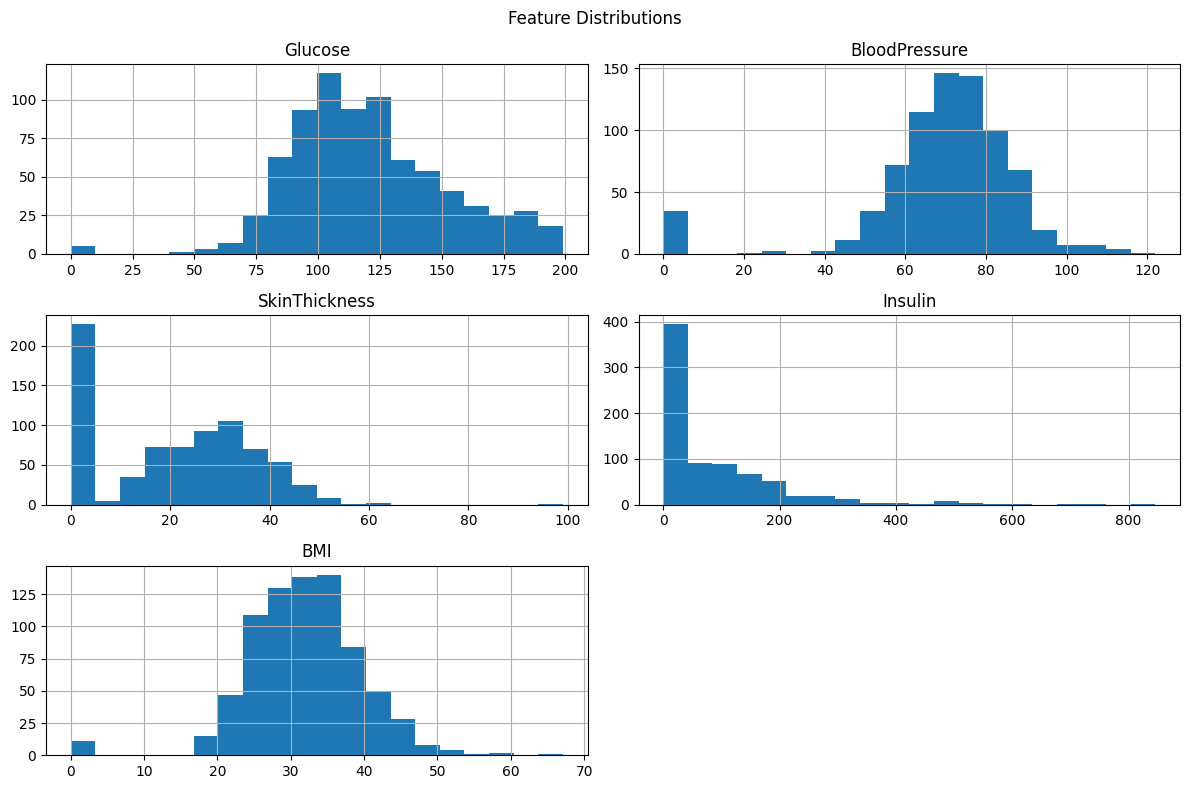

In [2]:
print("First 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

zero_columns = [
    'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI'
]

print("\nZero Values:")
print((df[zero_columns] == 0).sum())

df[zero_columns].hist(figsize=(12, 8), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

Task 3: Quantify and handle implicit missing values using SimpleImputer.


Here the machine handles missing values in specific features, they are replaced with NaN since the value 0 for glucose or BMI are not valid measurements. The set is then divided into training and testing, the SimpleImputer replaces the missing values using the median of each training. Median values are useful since its less affected by extreme values.


In [3]:
X = df.drop(columns=['Outcome']).copy()
y = df['Outcome']

X[zero_columns] = X[zero_columns].replace(0, np.nan)

print("Missing Values Before Imputation:")
print(X.isnull().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy='median')

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

print("\nMissing Values After Imputation:")
print(X_train_imputed.isnull().sum())

print("\nTraining Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Missing Values Before Imputation:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

Missing Values After Imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Training Set: (614, 8)
Testing Set: (154, 8)


Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.



Here we make a preprocessing pipeline using ColumnTransformer and Pipeline. It uses SimpleImputer to replace the missing values with the median values and StandardScale to make the numeric features standard. Here scaling is important for logistic regression and support vector machines since the performance can depend on feature magnitudes. The pipeline is first used with training data and then testing data since we need to maintain consistency and prevent data leakage.

In [4]:
numeric_features = X.columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nFirst 5 Processed Rows:")
print(X_train_processed[:5])

Training Data Shape: (614, 8)
Testing Data Shape: (154, 8)

First 5 Processed Rows:
[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76969431
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41771394
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.35957603
  -0.76486207 -0.70759409]
 [-0.85135507  0.81152492 -1.31593218 -0.00476614 -0.16143729 -0.40304809
   0.26231357 -0.36929331]
 [-1.15333775 -0.88964601 -0.66367599  1.12077551 -0.41556496  1.78216334
  -0.33762972 -0.96131967]]


Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.


For this task, we train two voting classifiers using logistic regression, support vector classification, and a decision tree. Hard voting determines the prediction through the majority voting while the soft voting predicts the probability to select the final classification. Both are evaluated through test accuracy and classification reports.


Hard Voting Accuracy: 0.7402597402597403
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154

Soft Voting Accuracy: 0.7272727272727273
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       100
           1       0.64      0.52      0.57        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg       0.72      0.73      0.72       154



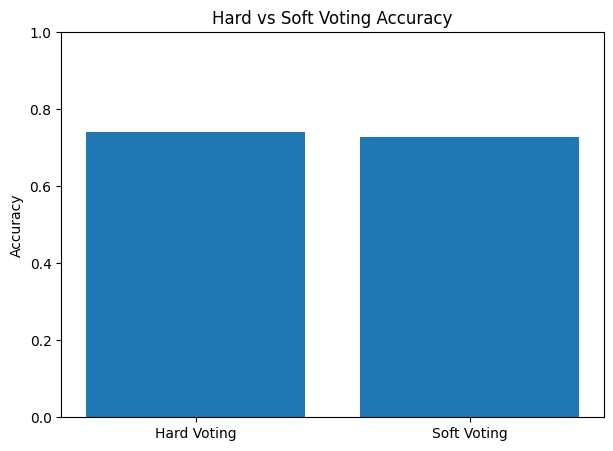

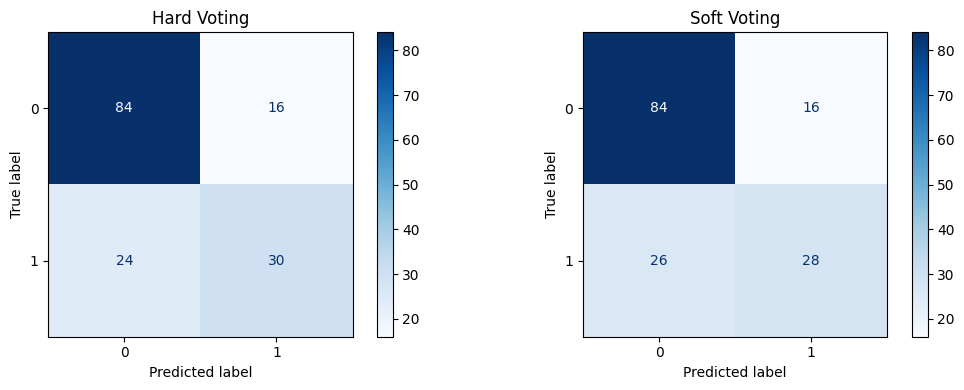

In [5]:
estimators = [
    ('lr', LogisticRegression(max_iter=2000, random_state=42)),
    ('svc', SVC(probability=True, random_state=42)),
    ('tree', DecisionTreeClassifier(max_depth=4, random_state=42))
]

hard_voting = VotingClassifier(
    estimators=estimators,
    voting='hard'
)

soft_voting = VotingClassifier(
    estimators=estimators,
    voting='soft'
)

hard_voting.fit(X_train_processed, y_train)
soft_voting.fit(X_train_processed, y_train)

hard_pred = hard_voting.predict(X_test_processed)
soft_pred = soft_voting.predict(X_test_processed)

hard_accuracy = accuracy_score(y_test, hard_pred)
soft_accuracy = accuracy_score(y_test, soft_pred)

print("Hard Voting Accuracy:", hard_accuracy)
print(classification_report(y_test, hard_pred))

print("Soft Voting Accuracy:", soft_accuracy)
print(classification_report(y_test, soft_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    ['Hard Voting', 'Soft Voting'],
    [hard_accuracy, soft_accuracy]
)
plt.ylabel("Accuracy")
plt.title("Hard vs Soft Voting Accuracy")
plt.ylim(0, 1)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, hard_pred, ax=axes[0], cmap='Blues'
)
axes[0].set_title("Hard Voting")

ConfusionMatrixDisplay.from_predictions(
    y_test, soft_pred, ax=axes[1], cmap='Blues'
)
axes[1].set_title("Soft Voting")

plt.tight_layout()
plt.show()

Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.


Now we implement a bagging classification using multiple decision trees trained on bootstrap samples. Bootstrap sampling are randomly selected with replacements allowing for different trees to learn from one another. Out of bag evaluations give an estimate on the model's performance based on observations. Comparing the out of bag score with test accuracy can help determine if the model generalizes effectively to hidden data.

OOB Accuracy: 0.754071661237785
Test Accuracy: 0.7337662337662337

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       100
           1       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



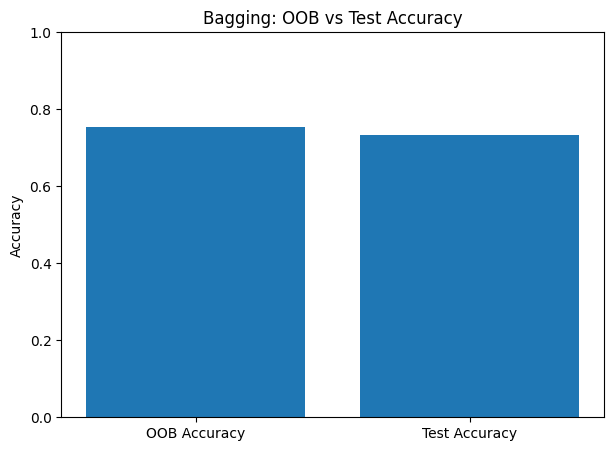

In [6]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

bagging.fit(X_train_processed, y_train)

bagging_pred = bagging.predict(X_test_processed)

bagging_accuracy = accuracy_score(y_test, bagging_pred)
oob_accuracy = bagging.oob_score_

print("OOB Accuracy:", oob_accuracy)
print("Test Accuracy:", bagging_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, bagging_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    ['OOB Accuracy', 'Test Accuracy'],
    [oob_accuracy, bagging_accuracy]
)
plt.ylabel("Accuracy")
plt.title("Bagging: OOB vs Test Accuracy")
plt.ylim(0, 1)
plt.show()

Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

Here, the command trains a random forest classifier which combines multiple decision trees. This improves prediction accuracy and reduces variance. Random forests uses a bootstrap sample and random feature subsetting, this allows the trees to learn different patterns. The model is then tested for its accuracy and a classification report.

Random Forest Accuracy: 0.7467532467532467

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.84      0.81       100
           1       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154


Feature Importances:
SkinThickness               0.073344
Pregnancies                 0.079317
BloodPressure               0.085172
Insulin                     0.091532
Age                         0.120007
DiabetesPedigreeFunction    0.124418
BMI                         0.158169
Glucose                     0.268040
dtype: float64


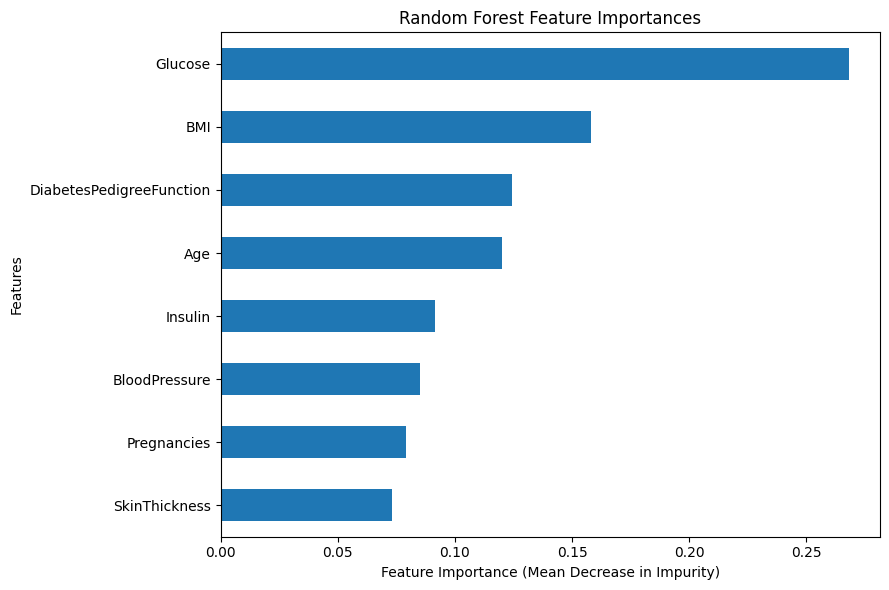

In [7]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

rf_pred = random_forest.predict(X_test_processed)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

importances = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values()

print("\nFeature Importances:")
print(importances)

plt.figure(figsize=(9, 6))
importances.plot(kind='barh')
plt.xlabel("Feature Importance (Mean Decrease in Impurity)")
plt.ylabel("Features")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

Finally, here we train the model with an adaboost classifier using decision stumps. Adaboost train models in a sequence and adjusts sample values to focus more on observation that previous classifiers misclassified.

AdaBoost Training Accuracy: 0.7980456026058632
AdaBoost Test Accuracy: 0.7467532467532467

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.82       100
           1       0.67      0.54      0.60        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154



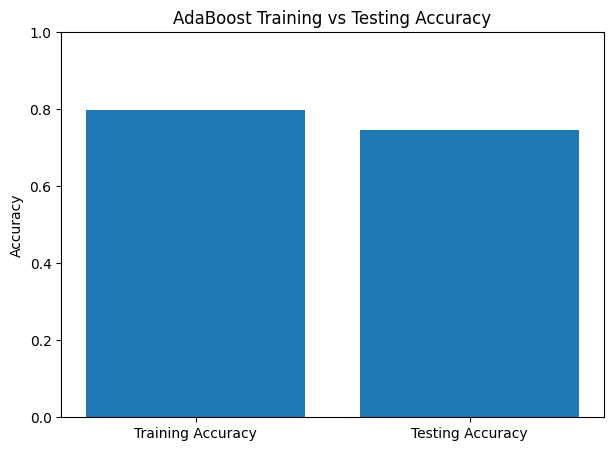

In [8]:
adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

adaboost.fit(X_train_processed, y_train)

ada_train_pred = adaboost.predict(X_train_processed)
ada_test_pred = adaboost.predict(X_test_processed)

ada_train_accuracy = accuracy_score(y_train, ada_train_pred)
ada_test_accuracy = accuracy_score(y_test, ada_test_pred)

print("AdaBoost Training Accuracy:", ada_train_accuracy)
print("AdaBoost Test Accuracy:", ada_test_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, ada_test_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    ['Training Accuracy', 'Testing Accuracy'],
    [ada_train_accuracy, ada_test_accuracy]
)
plt.ylabel("Accuracy")
plt.title("AdaBoost Training vs Testing Accuracy")
plt.ylim(0, 1)
plt.show()